# Phase 1: Support-set study

## Section 1 - Purpose and overview

Study of which and how many reference frames the prototypes need. Frames are chosen on validation (assembly_2, 1_disassembled_controlled_caos). The test sequence (assembly_1) is never read in this notebook. It was inspected once, in the qualitative evaluation of v1-baseline, before any change.

## Section 2 - Configuration

In [1]:
# 2.1 Run once per environment, then leave it commented
# %pip install -q shapely pandas scikit-learn einops scipy opencv-python

In [2]:
# 2.2 Imports
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
import transformers
import json 
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [3]:
# 2.3 Paths and shared module
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_support_set_study"
BASELINE_DIR = PROJECT_ROOT / "outputs" / "baseline"
BASELINE_PROTOTYPES_PATH = BASELINE_DIR / "prototypes_v1-baseline.npz"             # saved by the v1-baseline pipeline
BASELINE_SIMILARITIES_PATH = BASELINE_DIR / "test_similarities_v1-baseline.npz"    # saved by the v1-baseline pipeline

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "BASELINE_PROTOTYPES_PATH": BASELINE_PROTOTYPES_PATH,
                   "BASELINE_SIMILARITIES_PATH": BASELINE_SIMILARITIES_PATH}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), the same used by the pipeline notebook
from perception.classes import CLASS_NAMES, HAND_LABEL, PIECE_LABELS, IGNORE_ID, CLASS_COLORS, PATCH_LABEL_NAMES
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import build_prototypes, stack_prototypes, load_prototypes, assign_labels, classify_patches
from perception.labels import sequence_of, load_annotation, check_annotation, rasterize_annotation, patch_label_grid
from perception.visualization import label_grid_to_rgb

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] BASELINE_PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\baseline\prototypes_v1-baseline.npz
[OK] BASELINE_SIMILARITIES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\baseline\test_similarities_v1-baseline.npz


In [4]:
# 2.4 Hyperparameters
# Same values as the pipeline (phase_1_perception, Section 2.5): this study changes only the reference frames.

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5

# --- Classification ---
CONFIDENCE_MARGIN = 0.03        # provisional, from the pipeline: not tuned in this study (margin study)

# --- Regression check (Section 3) ---
DETERMINISM_FRAME = "assembly_2_f0003"   # any validation frame
N_DETERMINISM_RUNS = 3                   # forward passes on the same frame

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: errors are inspected and reference frames are chosen here.
# Test: held out until the end of all studies. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Support set of the v1-baseline pipeline (phase_1_perception, Section 4.1): the starting point of the study
BASELINE_REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
]

VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view"},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view"},
]

# No leakage: reference frames never come from validation or test sequences
for ref in BASELINE_REFERENCE_FRAMES:
    assert sequence_of(ref["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {ref['frame']}"
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    assert frame_path(val["frame"]).exists(), f"Missing frame: {val['frame']}"

# Annotated candidate reference frames (not validation): checked together with the validation frames
EXTRA_ANNOTATED_FRAMES = ["5_assembled_f0019"]

# Ground truth: every official class is evaluated; legacy labels (shoe, pants) become ignored patches
GT_LABELS = PIECE_LABELS | {HAND_LABEL}

print(f"{len(BASELINE_REFERENCE_FRAMES)} baseline reference frames, {len(VALIDATION_FRAMES)} validation frames")

7 baseline reference frames, 8 validation frames


In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


## Section 3 - Regression check against v1-baseline

The shared code was moved from the pipeline notebook to src/perception. This section checks that the module reproduces v1-baseline: same prototypes, same similarities and labels on the validation frames.

In [7]:
# 3.1 Loading the model (shared FeatureExtractor, same settings as the pipeline)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
PATCH_SIZE = extractor.patch_size
print(f"Model loaded, patch size {PATCH_SIZE}x{PATCH_SIZE}")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16


In [8]:
# 3.2 Determinism: does the same frame give the same features twice?
# If yes, the module can be compared with v1-baseline for exact equality.
image = Image.open(frame_path(DETERMINISM_FRAME)).convert("RGB")
runs = [extractor.extract(image)[0] for _ in range(N_DETERMINISM_RUNS)]
run_diffs = [float(np.abs(run - runs[0]).max()) for run in runs[1:]]

print(f"Frame: {DETERMINISM_FRAME}, {N_DETERMINISM_RUNS} forward passes")
print(f"Max absolute feature difference vs run 1: {run_diffs}")
print(f"Typical feature magnitude (median |value|): {np.median(np.abs(runs[0])):.4f}")
print("Deterministic: bitwise identical runs" if max(run_diffs) == 0 else
      "NOT bitwise deterministic: compare with a tolerance above the run-to-run difference")

Frame: assembly_2_f0003, 3 forward passes
Max absolute feature difference vs run 1: [0.0, 0.0]
Typical feature magnitude (median |value|): 0.4986
Deterministic: bitwise identical runs


Observation 3.2:
Three forward passes on the same frame (assembly_2_f0003) give bitwise identical features. Feature extraction is deterministic on this GPU and software setup. So the comparison with v1-baseline can require exact equality.

In [9]:
# 3.3 Prototypes: module vs v1-baseline file
# Same 7 reference frames, rebuilt with src/perception. Patch counts do not involve the GPU,
# so they must match exactly; prototype vectors are compared numerically.
for ref in BASELINE_REFERENCE_FRAMES:
    ref["image_path"], ref["json_path"] = frame_path(ref["frame"]), frame_path(ref["frame"], ".json")
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], ref["resized_size"] = extractor.extract(image)
    pixel_map = rasterize_annotation(ref["json_path"], ref["use_labels"], ref["resized_size"])
    ref["patch_labels"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

prototypes, patch_counts = build_prototypes(BASELINE_REFERENCE_FRAMES)
prototype_matrix = stack_prototypes(prototypes)

baseline = load_prototypes(BASELINE_PROTOTYPES_PATH)
assert baseline["class_names"] == CLASS_NAMES, "Class order differs from v1-baseline"

prototype_check = pd.DataFrame({
    "patches (v1)": baseline["patch_counts"],
    "patches (module)": [patch_counts[name] for name in CLASS_NAMES],
    "max |difference|": np.abs(prototype_matrix - baseline["prototypes"]).max(axis=1),
    "cosine(v1, module)": (prototype_matrix * baseline["prototypes"]).sum(axis=1),
}, index=CLASS_NAMES)
display(prototype_check)

print(f"Patch counts identical: {(prototype_check['patches (v1)'] == prototype_check['patches (module)']).all()}")
print(f"Prototypes bitwise identical: {np.array_equal(prototype_matrix, baseline['prototypes'])}")
print(f"Largest difference: {prototype_check['max |difference|'].max():.2e}, "
      f"lowest cosine: {prototype_check['cosine(v1, module)'].min():.8f}")

,patches (v1),patches (module),max |difference|,"cosine(v1, module)"
background,26744,26744,0.0,1.0
body,226,226,0.0,1.0
base,184,184,0.0,1.0
hat,38,38,0.0,1.0
eyes,24,24,0.0,1.0
ear,39,39,0.0,1.0
nose,23,23,0.0,1.0
moustache,27,27,0.0,1.0
mouth,20,20,0.0,1.0
arm_1,28,28,0.0,1.0


Patch counts identical: True
Prototypes bitwise identical: True
Largest difference: 0.00e+00, lowest cosine: 0.99999988


Observation 3.3:
The 7 reference frames give the same patch count per class as v1-baseline. The 12 prototypes are bitwise identical. The lowest cosine is 0.99999988 and not 1. This is float32 rounding of the dot product, since the vectors are identical.

In [10]:
# 3.4 Validation frames: similarities and labels, module vs v1-baseline
# The v1-baseline file stores raw similarities; labels are recomputed from them with the same margin.
baseline_similarities = np.load(BASELINE_SIMILARITIES_PATH)

rows = []
for val in VALIDATION_FRAMES:
    image = Image.open(frame_path(val["frame"])).convert("RGB")
    features, _ = extractor.extract(image)
    labels, similarities = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)

    similarities_v1 = baseline_similarities[f"{val['frame']}__similarities"]
    labels_v1 = assign_labels(similarities_v1, CONFIDENCE_MARGIN)
    rows.append({
        "frame": val["frame"],
        "max |similarity difference|": float(np.abs(similarities - similarities_v1).max()),
        "labels identical (%)": 100 * float((labels == labels_v1).mean()),
        "patches with a different label": int((labels != labels_v1).sum()),
    })

regression_table = pd.DataFrame(rows).set_index("frame")
display(regression_table)
print(f"All labels identical on the {len(VALIDATION_FRAMES)} validation frames: "
      f"{(regression_table['patches with a different label'] == 0).all()}")

,max |similarity difference|,labels identical (%),patches with a different label
frame,,,
assembly_2_f0003,0.0,100.0,0
assembly_2_f0017,0.0,100.0,0
assembly_2_f0030,0.0,100.0,0
assembly_2_f0046,0.0,100.0,0
assembly_2_f0057,0.0,100.0,0
assembly_2_f0068,0.0,100.0,0
1_disassembled_controlled_caos_f0001,0.0,100.0,0
1_disassembled_controlled_caos_f0016,0.0,100.0,0


All labels identical on the 8 validation frames: True


Observation 3.4:
On the 8 validation frames the similarities are bitwise identical to v1-baseline. All patch labels are identical. The refactored pipeline notebook runs end to end and gives the same outputs.

References Section 3: none. Numerical reproducibility on GPU: PyTorch documentation, Reproducibility notes (not a paper).

## Section 4 - Validation annotations

The 8 validation frames are annotated with labelme polygons, with the same rules as the reference frames. Every visible piece has its own polygon, and only the visible part is annotated. The body is annotated whole, and mounted pieces lie on top of it. The empty mouth slot is part of the body. Pants and shoes are base when mounted; separated pants and shoes (1_disassembled_controlled_caos) keep the legacy labels shoe and pants and become ignored patches. arm_1 is the arm with the open hand, arm_2 the one with the closed hand: they are told apart by shape, not by position. Everything else is background. 5_assembled_f0019, a candidate reference frame, was relabelled from shoe and pants to base.

In [11]:
# 4.1 Annotation inventory: polygons per label in each annotated frame.
# Read before check_annotation, so that old or misspelled labels are listed instead of stopping the cell.
rows = {}
for frame in [v["frame"] for v in VALIDATION_FRAMES] + EXTRA_ANNOTATED_FRAMES:
    json_path = frame_path(frame, ".json")
    if not json_path.exists():
        rows[frame] = {"file": "missing"}
        continue
    labels = [shape["label"] for shape in load_annotation(json_path)["shapes"]]
    rows[frame] = {"file": "ok", **pd.Series(labels).value_counts().to_dict()}

inventory = pd.DataFrame(rows).T.fillna(0)
display(inventory)

official = set(CLASS_NAMES) | {"file"}
print("Labels outside the official classes:", sorted(set(inventory.columns) - official))

C:\Users\ADV\AppData\Local\Temp\ipykernel_14372\3747387650.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  inventory = pd.DataFrame(rows).T.fillna(0)


,file,ear,hat,eyes,arm_2,arm_1,nose,moustache,mouth,body,base,hand,shoe,pants
assembly_2_f0003,ok,2,1,1,1,1,1,1,1,1,1,1,0,0
assembly_2_f0017,ok,2,1,1,1,1,1,1,1,1,1,0,0,0
assembly_2_f0030,ok,2,1,1,1,1,1,3,1,1,1,2,0,0
assembly_2_f0046,ok,2,1,1,1,1,1,1,1,1,1,2,0,0
assembly_2_f0057,ok,2,1,1,1,1,1,1,1,1,1,2,0,0
assembly_2_f0068,ok,2,1,1,1,1,1,1,1,1,1,3,0,0
1_disassembled_controlled_caos_f0001,ok,2,1,1,1,1,1,1,1,1,0,0,2,1
1_disassembled_controlled_caos_f0016,ok,2,1,1,1,1,1,1,1,1,0,0,2,1
5_assembled_f0019,ok,2,1,1,1,1,1,1,1,1,1,0,0,0


Labels outside the official classes: ['pants', 'shoe']


Observation 4.1:
All 8 validation frames are annotated. The only labels outside the official classes are shoe and pants, in the two frames of 1_disassembled_controlled_caos. In assembly_2_f0030 arm_1 is almost fully hidden by the hands: only its tip is annotated. The moustache held in hand is split by the fingers into 3 visible parts.

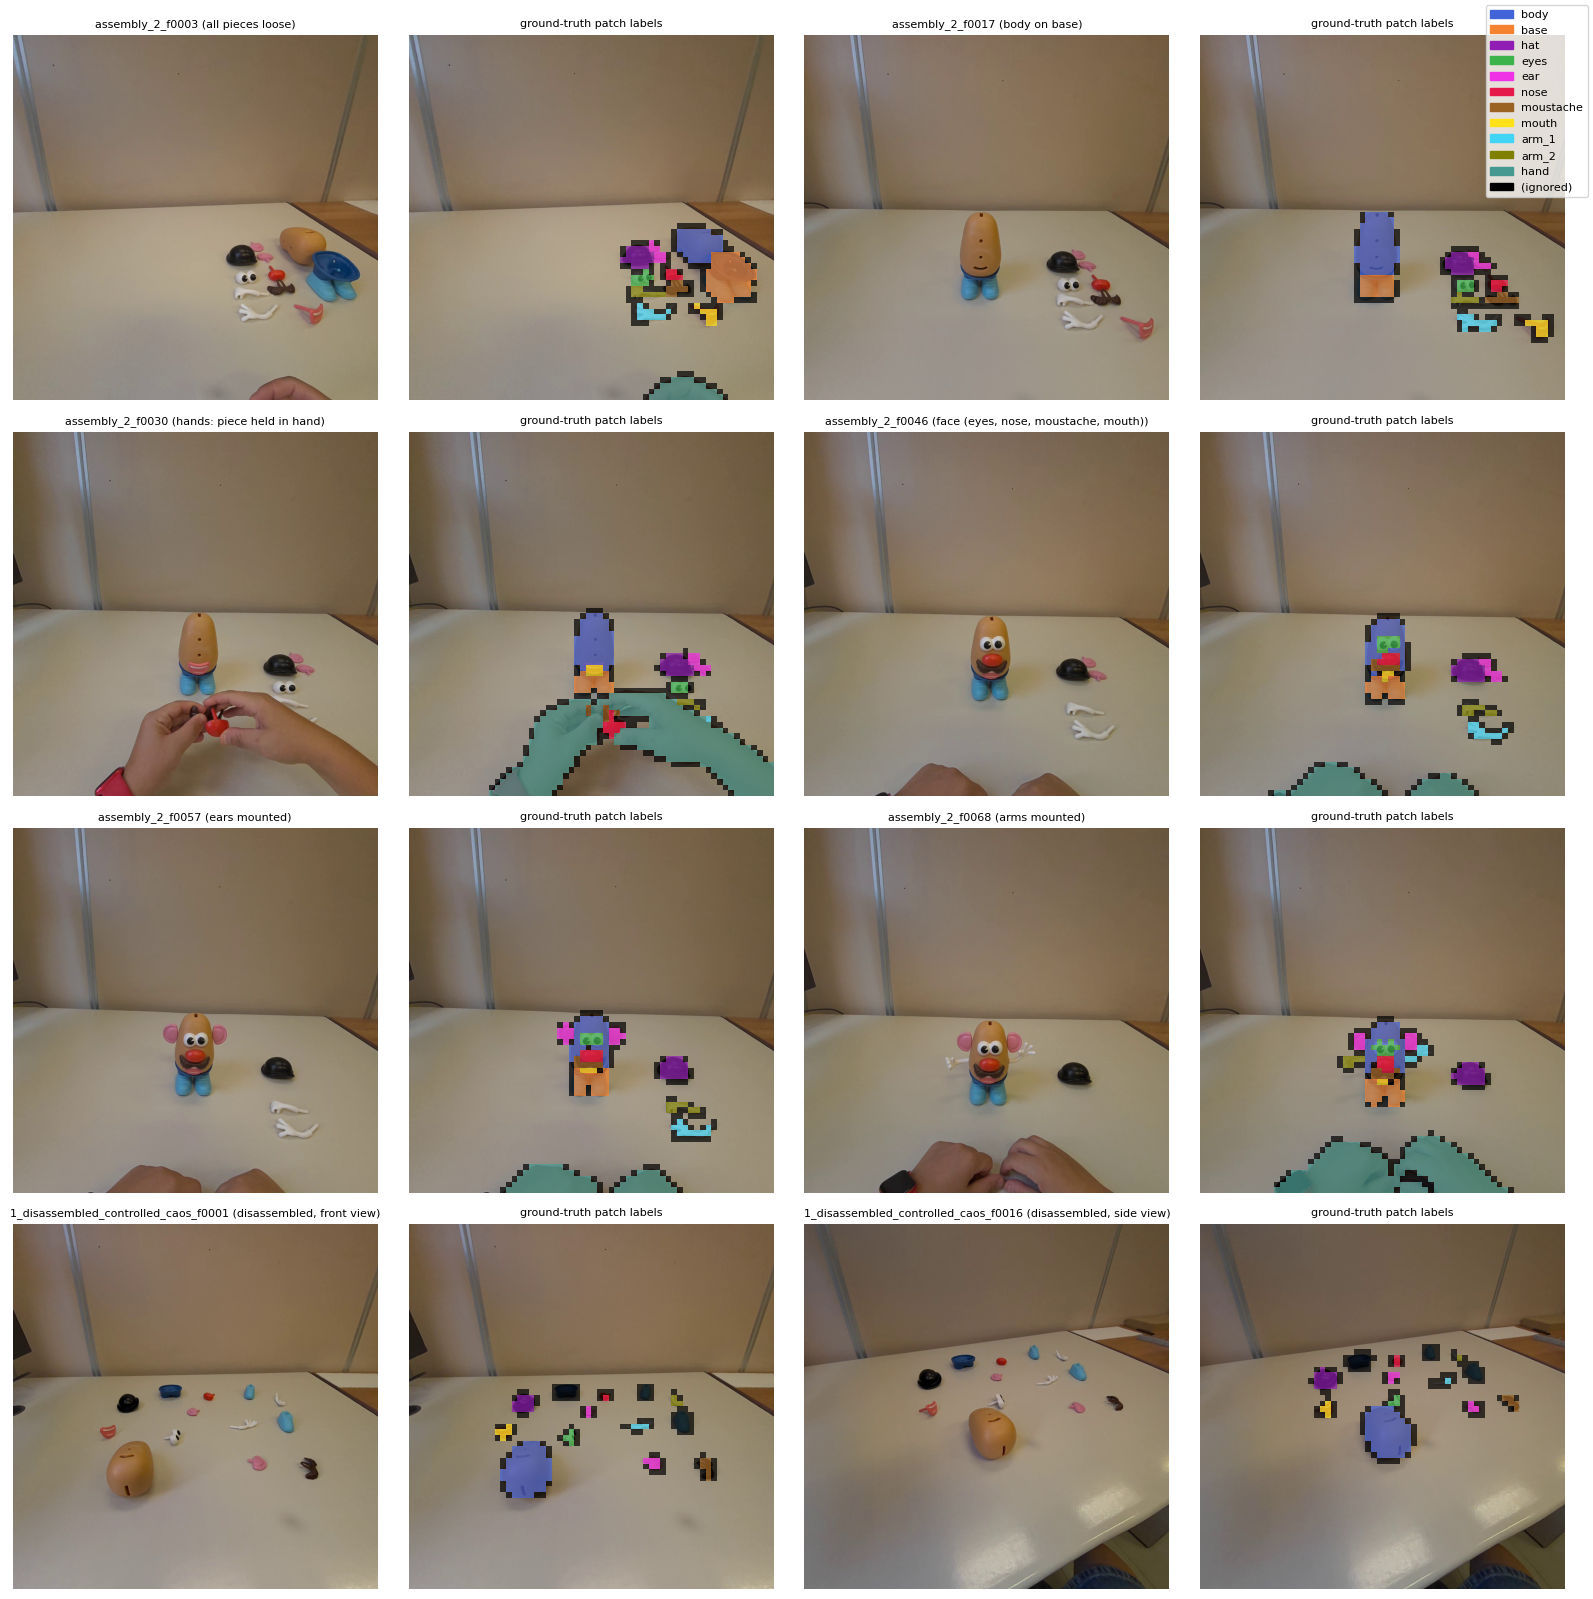

In [12]:
# 4.2 Ground-truth patch labels of the validation frames (same rules as the reference frames:
# majority >= MIN_LABEL_COVERAGE, mixed patches ignored). Background is left transparent.
for val in VALIDATION_FRAMES:
    image_path, json_path = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    check_annotation(image_path, json_path)
    with Image.open(image_path) as img:
        val["resized_size"] = extractor.input_size(img.width, img.height)
    pixel_map = rasterize_annotation(json_path, GT_LABELS, val["resized_size"])
    val["gt_labels"], _ = patch_label_grid(pixel_map, PATCH_SIZE, MIN_LABEL_COVERAGE)

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for ax in axes.flat:
    ax.axis("off")
for (ax_image, ax_gt), val in zip(axes.reshape(-1, 2), VALIDATION_FRAMES):
    image = Image.open(frame_path(val["frame"])).convert("RGB").resize(val["resized_size"])
    alpha = np.where(val["gt_labels"] == 0, 0.0, 0.7)[..., None]
    ax_image.imshow(image)
    ax_image.set_title(f"{val['frame']} ({val['stage']})", fontsize=8)
    ax_gt.imshow(image)
    ax_gt.imshow(np.concatenate([label_grid_to_rgb(val["gt_labels"]), alpha], axis=-1),
                 extent=(0, image.width, image.height, 0), interpolation="nearest")
    ax_gt.set_title("ground-truth patch labels", fontsize=8)

legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES[1:]]
legend.append(mpatches.Patch(color="black", label="(ignored)"))
fig.legend(handles=legend, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_ground_truth.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 4.2:
Ground-truth patch labels follow the objects in every frame. Boundary patches are ignored, as in the reference frames. Separated pants and shoes in 1_disassembled_controlled_caos are ignored. Jeans at the bottom of 1_disassembled_controlled_caos_f0016 are background.

In [14]:
# 4.3 Ground-truth patches per class: how many patches each class IoU will rest on
gt_counts = pd.DataFrame({
    val["frame"]: {name: int((val["gt_labels"] == i).sum()) for i, name in enumerate(PATCH_LABEL_NAMES)}
    for val in VALIDATION_FRAMES
}).T
gt_counts.loc["total"] = gt_counts.sum()
display(gt_counts)

,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand,(ignored)
assembly_2_f0003,3779,39,62,18,8,7,5,8,8,10,8,36,108
assembly_2_f0017,3829,69,24,17,6,6,5,8,8,12,6,0,106
assembly_2_f0030,3430,56,21,19,6,8,10,6,6,1,4,412,117
assembly_2_f0046,3787,34,23,21,10,8,7,6,3,11,8,91,87
assembly_2_f0057,3786,32,24,18,8,15,8,6,3,11,8,90,87
assembly_2_f0068,3621,34,25,19,10,12,8,7,2,6,6,247,99
1_disassembled_controlled_caos_f0001,3879,67,0,11,4,7,1,6,5,3,3,0,110
1_disassembled_controlled_caos_f0016,3883,60,0,13,3,6,2,5,4,1,1,0,118
total,29994,391,179,136,55,69,46,52,39,55,44,876,832


Observation 4.3:
The small pieces rest on few patches over the whole validation set: mouth 39, arm_2 44, nose 46, eyes 55, arm_1 55. Hand (876) and body (391) have the most. The two frames of 1_disassembled_controlled_caos contribute 1–7 patches per small piece, so results on small pieces depend mostly on assembly_2. 832 patches are ignored, mostly piece boundaries.

References Section 4: Ignored (void) regions excluded from evaluation: Everingham et al. 2010, Sect. 3.6.1 and 4.2.1 (a 5-pixel void border around objects, excluded from the per-class IoU); Cordts et al. 2016, Sect. 2.2 (void label when unclear, ignored in training and evaluation). Our ignored patches (mixed boundary patches, legacy labels) play the same role at patch level. Layered polygons: Cordts et al. 2016, Sect. 2.2.